In [16]:
import os, sys
REPO = "https://github.com/salsyaniditiani-commits/simuteh--2330511061-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

if not os.path.exists("data/sintetis/citra"):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Isi src:", os.listdir("../src"))

Folder kerja: /content/simuteh/notebook
Jumlah citra: 60
Isi src: ['utils_cv.py', 'praproses.py', 'buat_dataset_sintetis.py', '__pycache__']


Kode 4.1 Verifikasi konvolusi manual

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from utils_cv import baca, statistik, tampil, kontras_bercak

# Membaca citra dan mask
nama = "teh_041.png"

bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

# Fungsi konvolusi manual
def konvolusi(img, k):  # fungsi dari slide P4
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)

    return np.clip(np.round(out), 0, 255).astype(np.uint8)


# Fungsi konvolusi sejati
def konvolusi_sejati(img, k):  # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))


# Pengujian beberapa kernel
for nm, k in {
    "rerata": np.ones((3, 3)) / 9,
    "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
}.items():

    t0 = time.perf_counter()
    a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0

    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0

    beda = np.abs(a.astype(int) - b.astype(int)).max()

    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()

    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.353 s, filter2D=0.00052 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=2.321 s, filter2D=0.00051 s


Kode 4.2 Tabel penapis x derau x PSNR x waktu x KB

In [18]:
import pandas as pd
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):                  # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):        # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih,
20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0,
                  kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB",
                                     "waktu_ms", "KB"]).round(2)
print(tabel)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  3.64
1   gauss_10  rerata_3    36.97      0.20  6.12
2   gauss_10  rerata_5    38.11      0.24  6.33
3   gauss_10   gauss_5    37.86      0.47  6.30
4   gauss_10  median_3    35.53      0.14  6.00
5   gauss_10  median_5    38.58      1.06  6.89
6   gauss_10  median_9    38.95     18.92  7.52
7   gauss_20     tanpa    22.10      0.00  2.04
8   gauss_20  rerata_3    31.45      0.21  4.72
9   gauss_20  rerata_5    34.70      0.23  5.62
10  gauss_20   gauss_5    32.61      0.44  5.08
11  gauss_20  median_3    29.75      0.15  4.20
12  gauss_20  median_5    33.54      0.83  5.48
13  gauss_20  median_9    35.79     14.03  6.10
14  gauss_40     tanpa    16.33      0.00  1.02
15  gauss_40  rerata_3    25.80      0.15  2.86
16  gauss_40  rerata_5    29.83      0.17  4.06
17  gauss_40   gauss_5    27.03      0.28  3.21
18  gauss_40  median_3    23.83      0.09  2.35
19  gauss_40  median_5    27.88      0.7

grafik seluruh hasil

Kode 4.3 Pengaruh ukuran kernel median pada bercak kecil

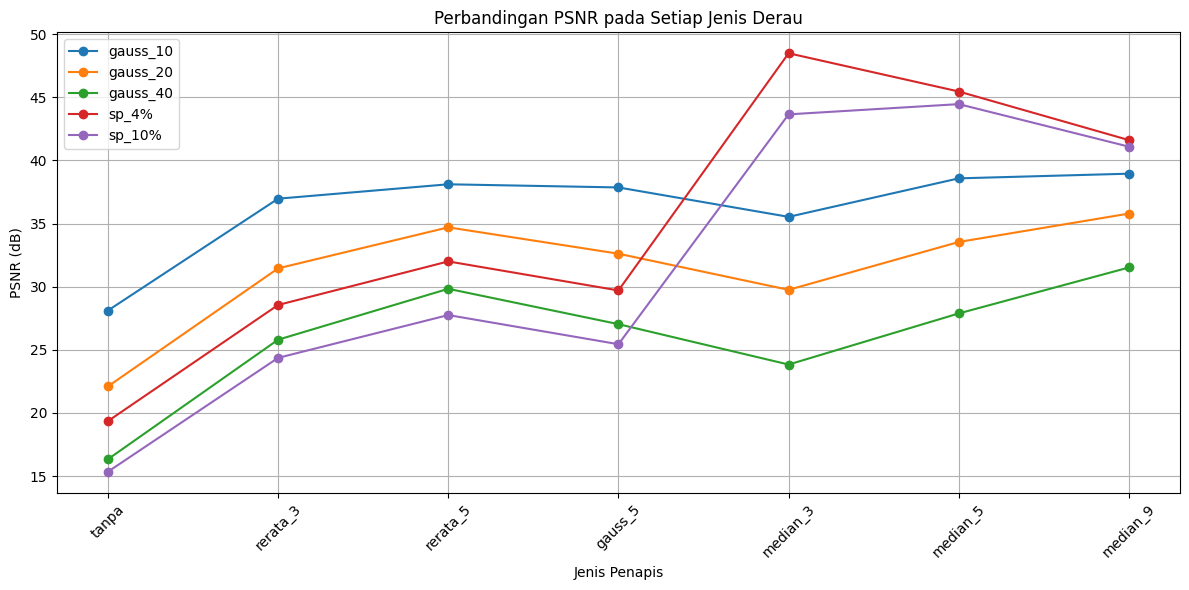

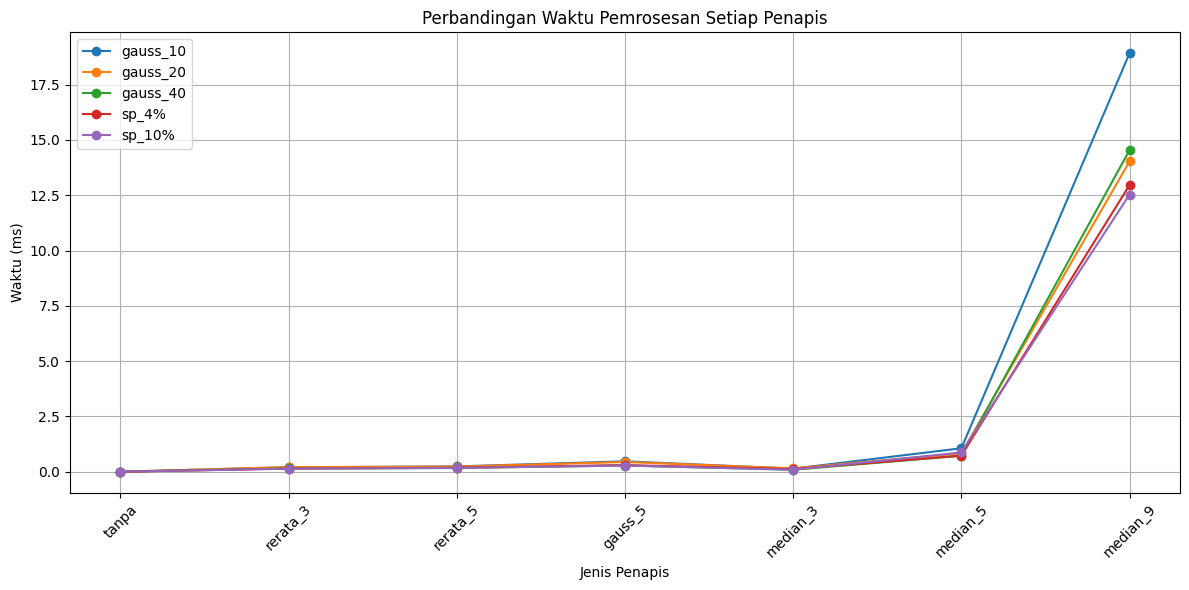

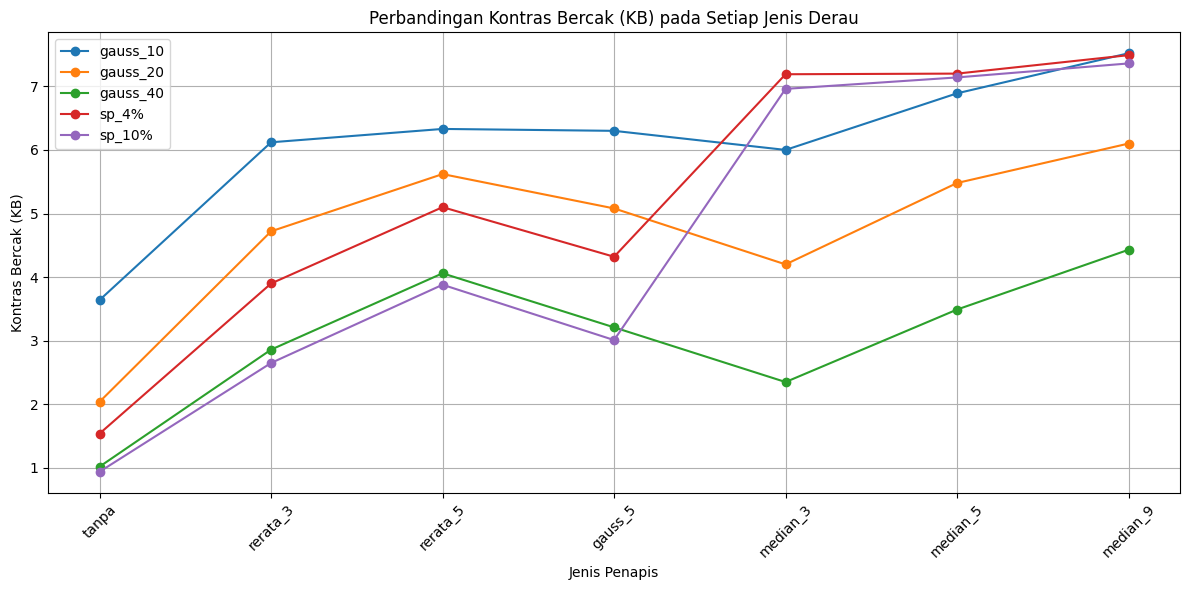

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import os

tabel = pd.read_csv("../hasil/b4_tabel_penapis.csv")

os.makedirs("../hasil", exist_ok=True)

# Grafik PSNR
plt.figure(figsize=(12, 6))
for derau in tabel["derau"].unique():
    data = tabel[tabel["derau"] == derau]
    plt.plot(data["penapis"], data["PSNR_dB"], marker="o", label=derau)

plt.title("Perbandingan PSNR pada Setiap Jenis Derau")
plt.xlabel("Jenis Penapis")
plt.ylabel("PSNR (dB)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../hasil/b4_grafik_psnr.png", dpi=200)
plt.show()


# Grafik waktu pemrosesan
plt.figure(figsize=(12, 6))
for derau in tabel["derau"].unique():
    data = tabel[tabel["derau"] == derau]
    plt.plot(data["penapis"], data["waktu_ms"], marker="o", label=derau)

plt.title("Perbandingan Waktu Pemrosesan Setiap Penapis")
plt.xlabel("Jenis Penapis")
plt.ylabel("Waktu (ms)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../hasil/b4_grafik_waktu.png", dpi=200)
plt.show()


# Grafik Kontras Bercak (KB)
plt.figure(figsize=(12, 6))
for derau in tabel["derau"].unique():
    data = tabel[tabel["derau"] == derau]
    plt.plot(data["penapis"], data["KB"], marker="o", label=derau)

plt.title("Perbandingan Kontras Bercak (KB) pada Setiap Jenis Derau")
plt.xlabel("Jenis Penapis")
plt.ylabel("Kontras Bercak (KB)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../hasil/b4_grafik_kb.png", dpi=200)
plt.show()

In [20]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:          # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2),
                      kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
print(hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2))

           dI    KB
kernel             
1       25.84  3.91
3       26.43  4.06
5       25.78  4.02
9       20.06  3.62
15       8.05  2.13


grafik terhadap ukuran kernel

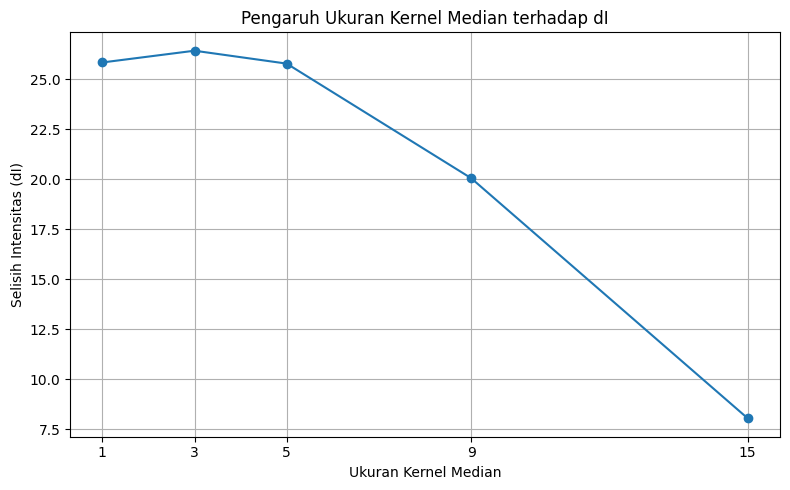

In [21]:
import matplotlib.pyplot as plt

rata_median = hasil_median.groupby("kernel")[["dI", "KB"]].mean()

plt.figure(figsize=(8, 5))
plt.plot(rata_median.index, rata_median["dI"], marker="o")
plt.title("Pengaruh Ukuran Kernel Median terhadap dI")
plt.xlabel("Ukuran Kernel Median")
plt.ylabel("Selisih Intensitas (dI)")
plt.xticks([1, 3, 5, 9, 15])
plt.grid(True)
plt.tight_layout()
plt.savefig("../hasil/b4_grafik_di_median.png", dpi=200)
plt.show()

ini yang bercak

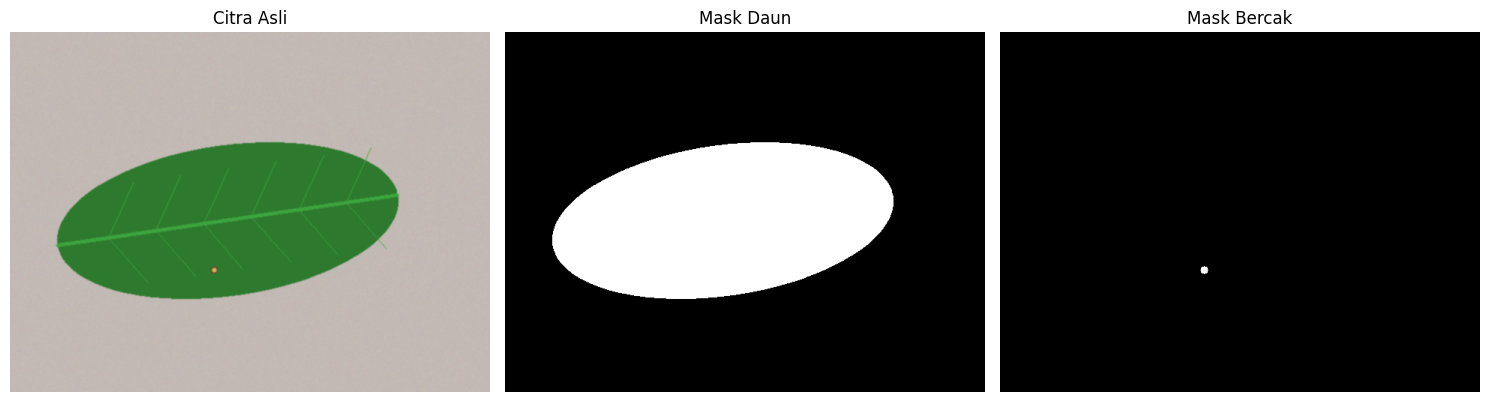

Nama citra: teh_021.png
Ukuran citra: (480, 640, 3)


In [22]:
import cv2
import matplotlib.pyplot as plt
from utils_cv import baca

# Ambil satu citra kelas ringan
nama = label[label.kelas == "ringan"].nama_file.iloc[0]

img = baca(f"../data/sintetis/bersih/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

# Tampilkan citra dan mask
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
ax[0].set_title("Citra Asli")

ax[1].imshow(md, cmap="gray")
ax[1].set_title("Mask Daun")

ax[2].imshow(mb, cmap="gray")
ax[2].set_title("Mask Bercak")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

print("Nama citra:", nama)
print("Ukuran citra:", img.shape)

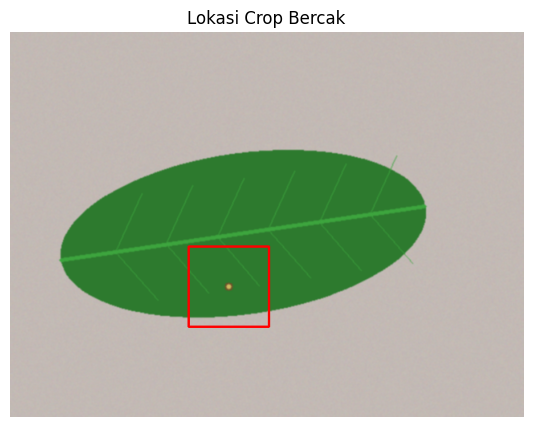

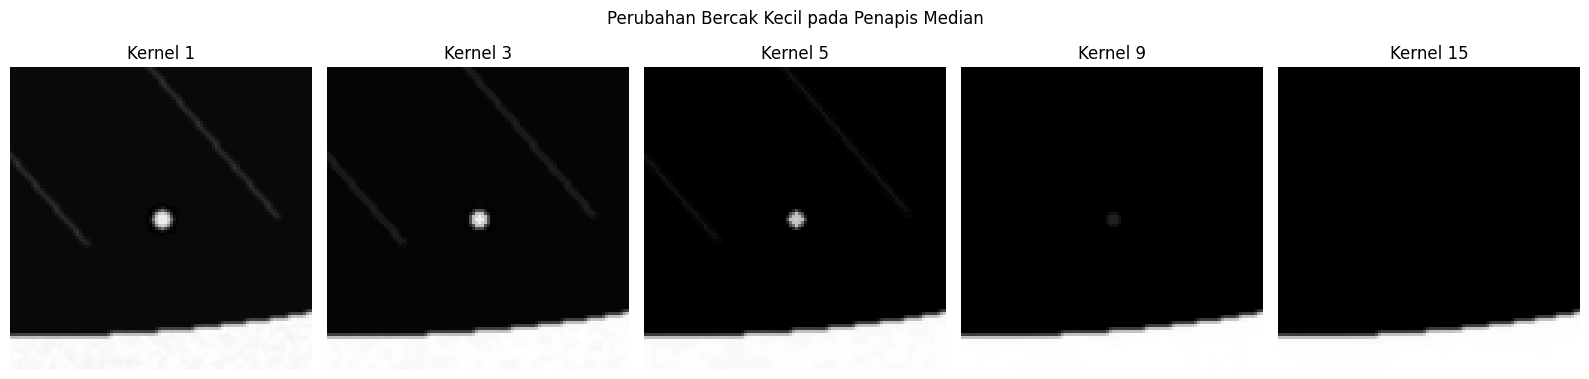

Koordinat crop: 222 267 322 367


In [23]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Cari posisi bercak dari mask
ys, xs = np.where(mb > 0)

# Tentukan titik tengah bercak
cx = int(xs.mean())
cy = int(ys.mean())

# Tentukan ukuran crop
ukuran = 100
x1 = max(0, cx - ukuran // 2)
y1 = max(0, cy - ukuran // 2)
x2 = min(img.shape[1], x1 + ukuran)
y2 = min(img.shape[0], y1 + ukuran)

# Tampilkan lokasi crop pada citra asli
gambar_crop = cv2.cvtColor(img.copy(), cv2.COLOR_BGR2RGB)
cv2.rectangle(gambar_crop, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(7, 5))
plt.imshow(gambar_crop)
plt.title("Lokasi Crop Bercak")
plt.axis("off")
plt.show()

# Crop citra setelah setiap ukuran kernel diterapkan
g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel_list = [1, 3, 5, 9, 15]

fig, ax = plt.subplots(1, 5, figsize=(16, 4))

for i, k in enumerate(kernel_list):
    hasil = g if k == 1 else cv2.medianBlur(g, k)
    crop = hasil[y1:y2, x1:x2]

    ax[i].imshow(crop, cmap="gray")
    ax[i].set_title(f"Kernel {k}")
    ax[i].axis("off")

plt.suptitle("Perubahan Bercak Kecil pada Penapis Median")
plt.tight_layout()
plt.savefig("../hasil/b4_crop_median.png", dpi=200)
plt.show()

print("Koordinat crop:", x1, y1, x2, y2)

Kode 4.4 Pengaruh urutan penajaman

In [29]:
bersih = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
np.random.seed(42)
noise = np.random.normal(0, 20, bersih.shape)

noisy = np.clip(
    bersih.astype(np.float32) + noise,
    0, 255
).astype(np.uint8)
latar = mb == 0

def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

for nm, redam in {
    "Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "Median": lambda x: cv2.medianBlur(x, 5)
}.items():

    A = redam(unsharp(noisy))
    B = unsharp(redam(noisy))

    print(
        f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
        f"sigma_latar={A[latar].std():.1f} | redam->tajam "
        f"PSNR={cv2.PSNR(bersih, B):.2f} "
        f"sigma_latar={B[latar].std():.1f}"
    )

Gaussian: tajam->redam PSNR=30.37 sigma_latar=41.3 | redam->tajam PSNR=30.22 sigma_latar=41.5
Median: tajam->redam PSNR=30.24 sigma_latar=41.4 | redam->tajam PSNR=31.20 sigma_latar=41.3


In [25]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Daftar 12 citra kondisi normal
daftar_nama = [f"teh_{i:03d}.png" for i in range(1, 57, 5)]

# Penapis pilihan
nama_penapis = "median_3"
penapis = lambda x: cv2.medianBlur(x, 3)

baris = []

for nama in daftar_nama:
    # Membaca citra bersih dan citra dengan derau sensor
    bersih = cv2.imread(f"../data/sintetis/bersih/{nama}")
    noisy = cv2.imread(f"../data/sintetis/citra/{nama}")

    if bersih is None or noisy is None:
        print(f"Citra tidak ditemukan: {nama}")
        continue

    if bersih.shape != noisy.shape:
        print(f"Ukuran citra berbeda: {nama}")
        continue

    # PSNR sebelum penapisan
    psnr_sebelum = cv2.PSNR(bersih, noisy)

    # Terapkan penapis
    hasil = penapis(noisy)

    # PSNR sesudah penapisan
    psnr_sesudah = cv2.PSNR(bersih, hasil)

    baris.append([nama, psnr_sebelum, psnr_sesudah,
                  psnr_sesudah - psnr_sebelum])

hasil_sensor = pd.DataFrame(
    baris,
    columns=["nama", "PSNR_sebelum", "PSNR_sesudah", "peningkatan"]
)

print(hasil_sensor.round(2))

print("\nRata-rata PSNR:")
print(hasil_sensor[["PSNR_sebelum", "PSNR_sesudah", "peningkatan"]].mean().round(2))

hasil_sensor.to_csv("../hasil/b4_evaluasi_derau_sensor.csv", index=False)

           nama  PSNR_sebelum  PSNR_sesudah  peningkatan
0   teh_001.png         26.67         34.18         7.51
1   teh_006.png         31.52         38.66         7.14
2   teh_011.png         27.08         34.57         7.49
3   teh_016.png         26.82         34.30         7.48
4   teh_021.png         25.26         32.82         7.55
5   teh_026.png         25.42         32.96         7.54
6   teh_031.png         28.21         35.62         7.41
7   teh_036.png         29.07         36.37         7.30
8   teh_041.png         26.42         33.88         7.45
9   teh_046.png         32.41         39.26         6.85
10  teh_051.png         28.97         36.23         7.26
11  teh_056.png         32.16         39.14         6.98

Rata-rata PSNR:
PSNR_sebelum    28.33
PSNR_sesudah    35.66
peningkatan      7.33
dtype: float64


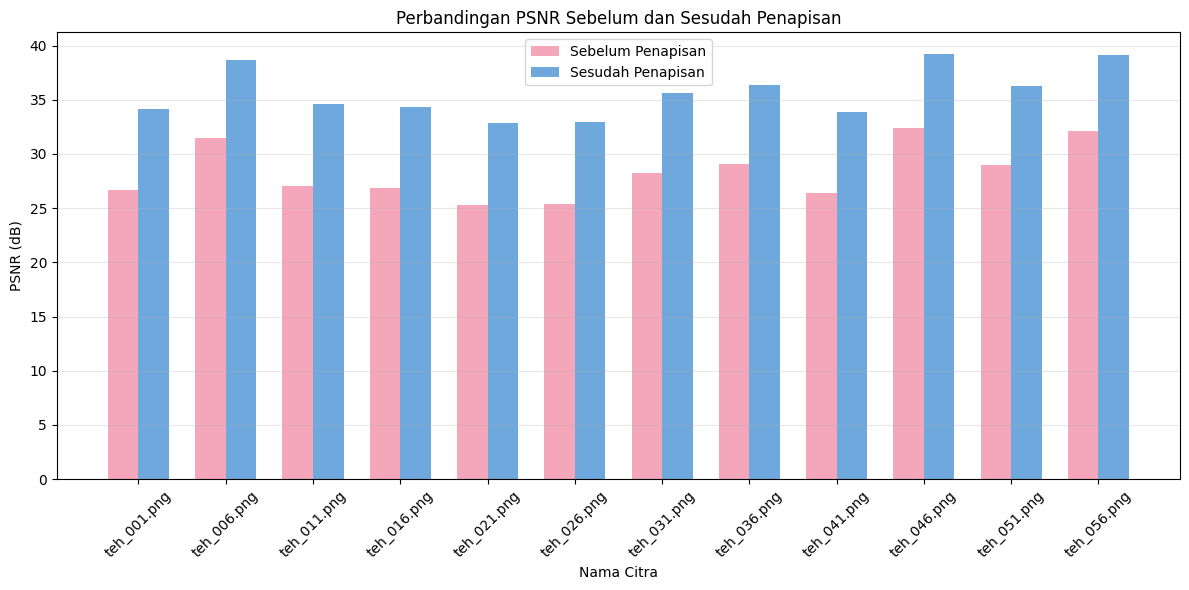

In [26]:
plt.figure(figsize=(12, 6))

x = np.arange(len(hasil_sensor))
lebar = 0.35

plt.bar(x - lebar/2, hasil_sensor["PSNR_sebelum"],
        lebar, label="Sebelum Penapisan", color="#F4A7BB")

plt.bar(x + lebar/2, hasil_sensor["PSNR_sesudah"],
        lebar, label="Sesudah Penapisan", color="#6FA8DC")

plt.title("Perbandingan PSNR Sebelum dan Sesudah Penapisan")
plt.xlabel("Nama Citra")
plt.ylabel("PSNR (dB)")
plt.xticks(x, hasil_sensor["nama"], rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../hasil/b4_grafik_psnr_sensor.png", dpi=200)
plt.show()